# 이커머스 멀티 모달 데이터 분석과 RFM

H&M 실제 거래의 시간 분산 구간 표본과 인기 상품 128개를 사용합니다. 입력은 원 데이터의 상품명/범주/가격/날짜/사진입니다. 구매 기록을 생성하지 않았습니다. 전체 고객 이력을 확보한 것은 아니므로 세분화와 코호트를 부분 관측 결과로 해석합니다.

데이터 준비: 저장소 루트에서 `python -m src.dataset --output data`를 실행합니다. 원본 CSV와 사진은 재배포하지 않습니다.


In [1]:
from pathlib import Path
import sys
project = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(project))
import numpy as np
import pandas as pd
from IPython.display import display, Image
from src.pipeline import DataAnalyzer
np.random.seed(42)
analyzer = DataAnalyzer(project/'data/analysis_transactions.csv', project/'data/images')
df = analyzer.load_data()
df['image_available'] = df.article_id.isin(analyzer.image_ids)
print('rows, columns:',df.shape)
print('observed images:',len(analyzer.image_ids),'missing products:',len(analyzer.image_failures))
df.info()
display(df.head())
display(df.select_dtypes(include='number').describe())


rows, columns: (16739, 16)
observed images: 126 missing products: 2
<class 'pandas.DataFrame'>
RangeIndex: 16739 entries, 0 to 16738
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   order_date        16739 non-null  datetime64[us]
 1   customer_id       16739 non-null  str           
 2   article_id        16739 non-null  str           
 3   price             16739 non-null  float64       
 4   sales_channel_id  16739 non-null  int64         
 5   product_name      16739 non-null  str           
 6   category          16739 non-null  str           
 7   colour            16739 non-null  str           
 8   department        16739 non-null  str           
 9   detail_desc       16739 non-null  str           
 10  name_length       16739 non-null  int64         
 11  word_count        16739 non-null  int64         
 12  image_mean        16259 non-null  float64       
 13  image_std         1

,order_date,customer_id,article_id,price,sales_channel_id,product_name,category,colour,department,detail_desc,name_length,word_count,image_mean,image_std,image_edge,image_available
0,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,0685687004,0.016932,2,W YODA KNIT OL OFFER,Sweater,Dark Green,Campaigns,V-neck knitted jumper with long sleeves and ri...,20,5,0.621751,0.352062,0.064141,True
1,2018-09-20,00402f4463c8dc1b3ee54abfdea280e96cd87320449eca...,0507909001,0.025407,1,Rebecca or Delphine shirt,Shirt,White,Blouse,Gently tailored shirt in a stretch cotton blen...,25,4,0.911659,0.023570,0.008499,True
2,2018-09-20,00609a1cc562140fa87a6de432bef9c9f0b936b259ad30...,0673677002,0.016932,2,Henry polo. (1),Sweater,Black,Knitwear,"Jumper in a soft, fine knit with a ribbed polo...",15,3,0.534972,0.405541,0.057423,True
3,2018-09-20,00609a1cc562140fa87a6de432bef9c9f0b936b259ad30...,0611415001,0.016932,2,Charlotte Brazilian Aza.Low 2p,Underwear bottom,Black,Expressive Lingerie,"Brazilian briefs in lace with a low waist, lin...",30,4,0.710241,0.333560,0.078178,True
4,2018-09-20,00ac5119d21281802ecd309e8c7fa0b598e0be861f21ca...,0610776002,0.008458,2,Tilly (1),T-shirt,Black,Jersey Basic,T-shirt in lightweight jersey with a rounded h...,9,2,NaN,NaN,NaN,False


,price,sales_channel_id,name_length,word_count,image_mean,image_std,image_edge
count,16739.000000,16739.000000,16739.000000,16739.000000,16259.000000,16259.000000,16259.000000
mean,0.021256,1.687138,17.487006,3.267101,0.723063,0.276088,0.048599
std,0.010402,0.463673,6.131977,1.214157,0.105699,0.115621,0.020274
min,0.001339,1.000000,5.000000,1.000000,0.289093,0.015205,0.005500
25%,0.013542,1.000000,13.000000,2.000000,0.654670,0.218039,0.041317
50%,0.018712,2.000000,16.000000,3.000000,0.716009,0.324470,0.049356
75%,0.029458,2.000000,24.000000,4.000000,0.798981,0.360754,0.059928
max,0.050831,2.000000,30.000000,6.000000,0.915873,0.406381,0.127631


## 데이터 구조의 해석

거래 16,739행, 상품 128개, 고객 11,372명의 표본입니다. 사진은 126개이며 없는 상품 2개가 480행에 영향을 줍니다. 따라서 사진 수와 거래 행 수를 같은 분모로 해석하지 않습니다.

가격 평균 0.021256, 중앙값 0.018712, 표준편차 0.010402입니다. 가격은 정규화 단위여서 원화/달러 매출로 전환할 수 없습니다. 실제 화폐 단위 확인 전에는 절대 금액의 사업 규모를 추정하지 않습니다.


## NumPy 이미지/텍스트 피처

사진 입력만 `imread`를 사용하고 축소는 NumPy 슬라이싱/경계 패딩으로 처리합니다. 평균, 표준편차, 히스토그램과 차분 엣지 통계는 N,H,W,C 배열 전체를 벡터 연산합니다. 파일 입력의 반복과 픽셀 통계의 반복을 구분했습니다.


image batch: (126, 32, 32, 3)
histogram shape: (126, 16)


,product_name,name_length,word_count,image_mean,image_std,image_edge
0,W YODA KNIT OL OFFER,20,5,0.621751,0.352062,0.064141
1,Rebecca or Delphine shirt,25,4,0.911659,0.023570,0.008499
2,Henry polo. (1),15,3,0.534972,0.405541,0.057423
3,Charlotte Brazilian Aza.Low 2p,30,4,0.710241,0.333560,0.078178
4,Tilly (1),9,2,NaN,NaN,NaN


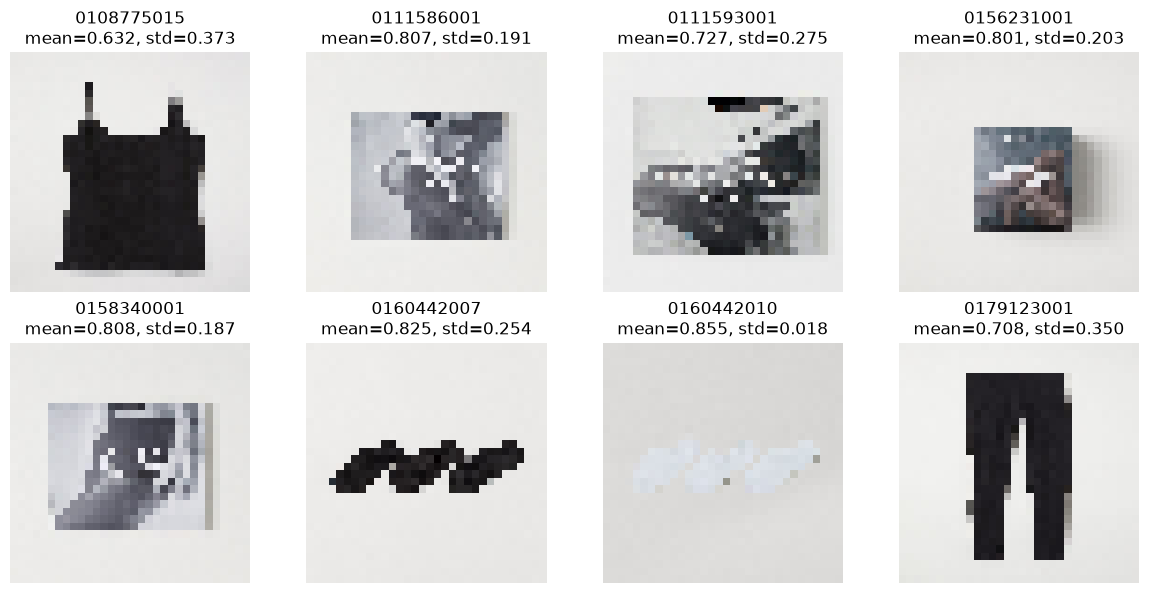

In [2]:
features = analyzer.image_statistics(analyzer.images)
print('image batch:',analyzer.images.shape)
print('histogram shape:',features['histogram'].shape)
np.testing.assert_allclose(features['histogram'].sum(axis=1),1)
display(df[['product_name','name_length','word_count','image_mean','image_std','image_edge']].head())
import matplotlib.pyplot as plt
fig,axes = plt.subplots(2,4,figsize=(12,6))
for index,ax in enumerate(axes.flat):
    ax.imshow(analyzer.images[index])
    ax.set_title(f'{analyzer.image_ids[index]}\nmean={features["image_mean"][index]:.3f}, std={features["image_std"][index]:.3f}')
    ax.axis('off')
fig.tight_layout()
fig.savefig(project/'outputs/image-features.png',dpi=150)
plt.show()


## 그룹 통계 기반 결측 대치

원본 가격/거래를 보존하고, 사진이 없는 상품의 파생 피처만 category 평균으로 대치합니다. 그룹이 모두 비어 있을 때는 전체 통계로 보완하며 전체 열이 비어 있으면 예외를 발생시킵니다. 관측 사진이 없는 행은 별도 플래그를 유지합니다.


In [3]:
print('missing before:',df[['image_mean','image_std','image_edge']].isna().sum().to_dict())
result = analyzer.handle_missing_values(columns=['image_mean','image_std','image_edge'])
print(result)
assert not analyzer.df[['image_mean','image_std','image_edge']].isna().any().any()


missing before: {'image_mean': 480, 'image_std': 480, 'image_edge': 480}
{'before': {'image_mean': 480, 'image_std': 480, 'image_edge': 480}, 'after': {'image_mean': 0, 'image_std': 0, 'image_edge': 0}}


## IQR와 통계 분석

가격의 IQR 경계에서는 이상치가 0건입니다. 이미지 밝기에서는 206행이 경계 밖에 있어 전후 분포를 함께 확인합니다. 사진의 어두운 색상이 실제 상품 특성일 수 있으므로 이를 오류로 단정해 고객 거래를 삭제하지 않습니다.

가격/단어 수 상관계수는 0.2428, 가격/관측 이미지 밝기는 -0.0044입니다. 전자는 카테고리 구성 효과가 섞여 있고 후자는 선형 상관이 거의 없으므로 이미지의 평균 밝기만으로 가격을 설명하기 어렵습니다.


price bounds: (-0.010330508474576275, 0.05333050847457627) outliers: 0
brightness bounds: (0.44839218239379103, 1.0011852787990196) outliers: 206
correlations: {'price_word_count': 0.24276810240735539, 'price_image_mean': -0.004372270195836988}


,price,name_length,image_mean
mean,0.021256,17.487006,0.723271
median,0.018712,16.000000,0.718652
std,0.010402,6.131977,0.104180


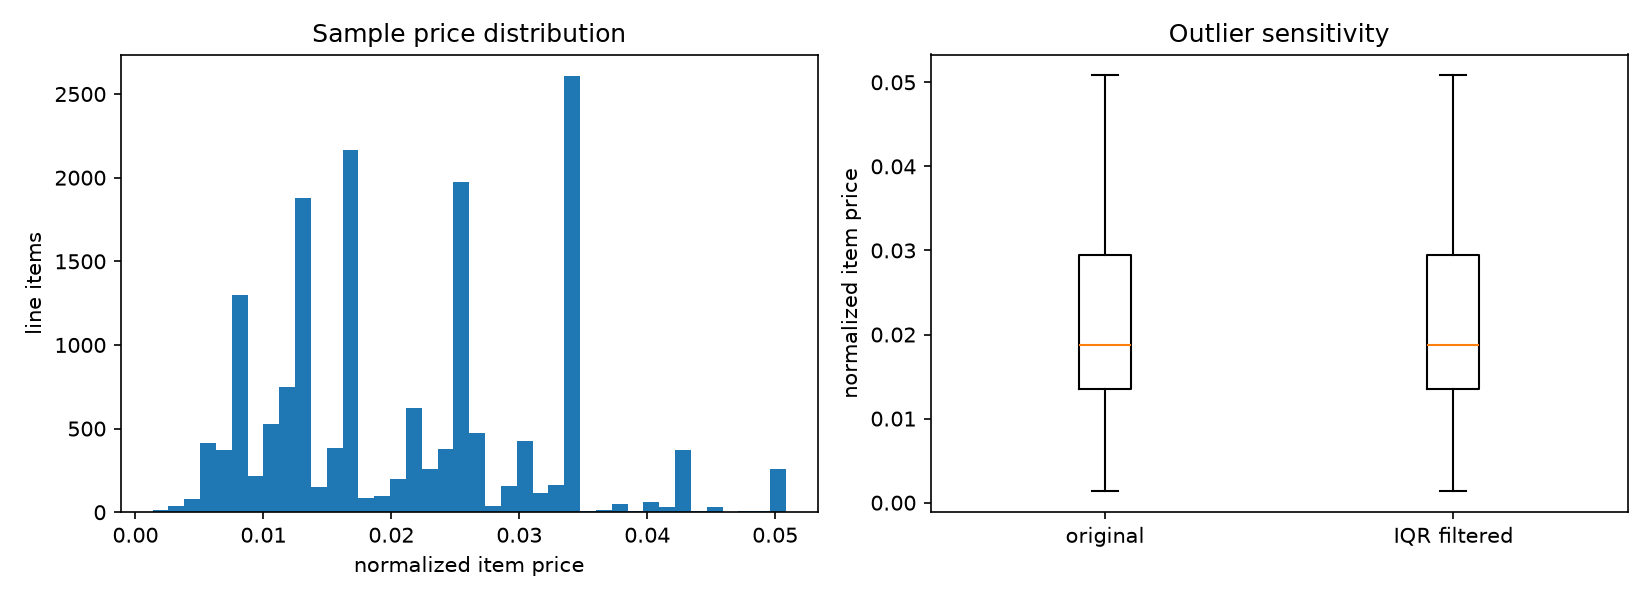

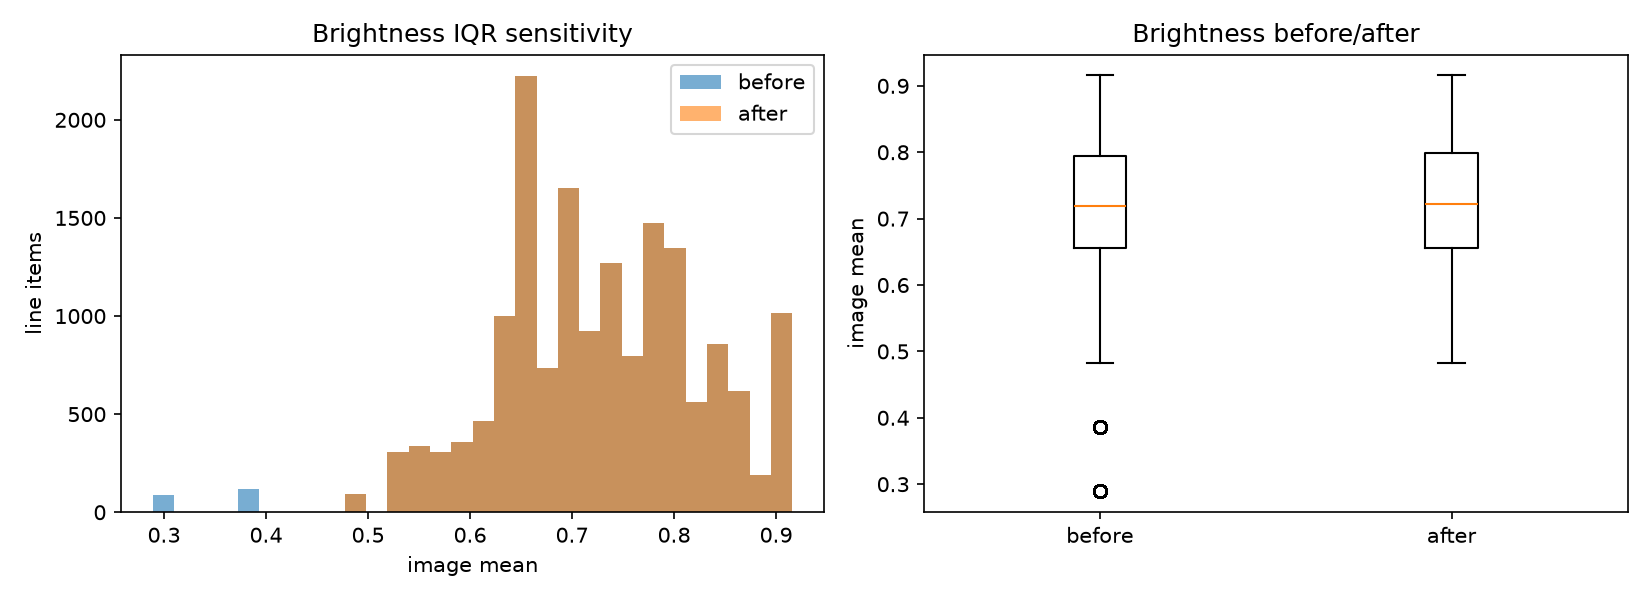

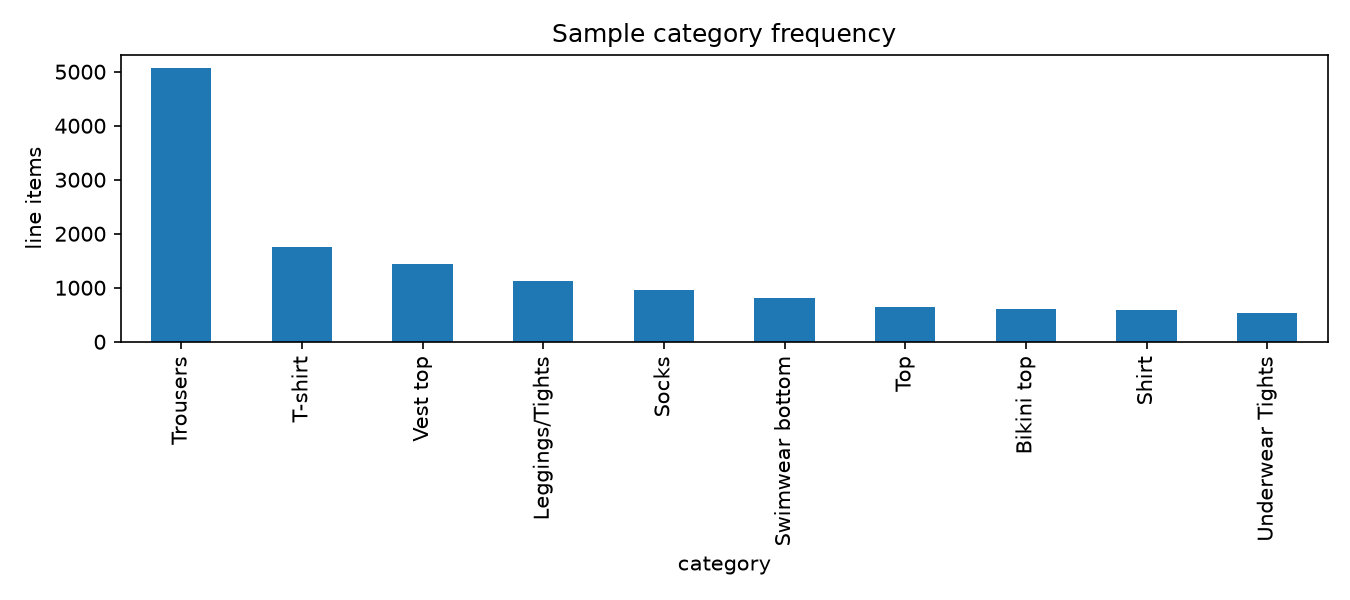

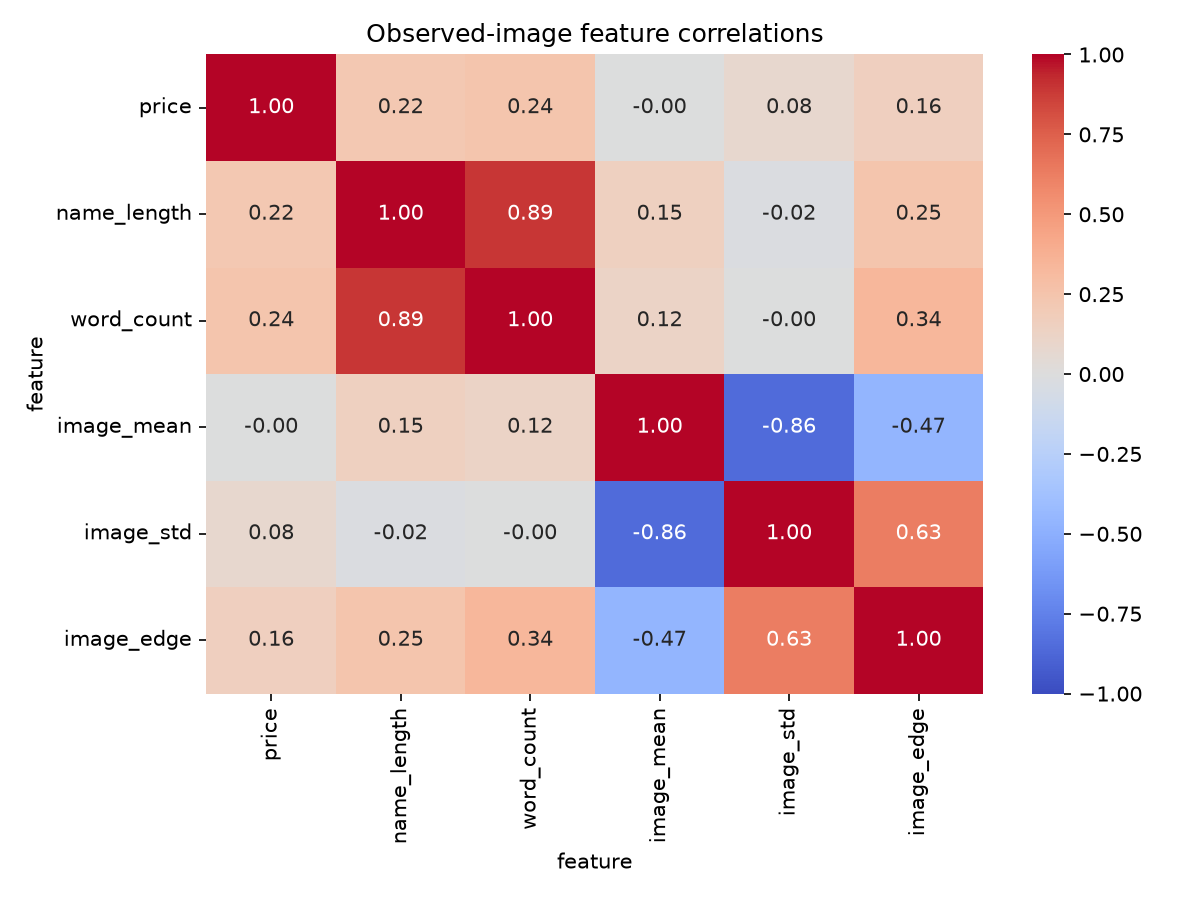

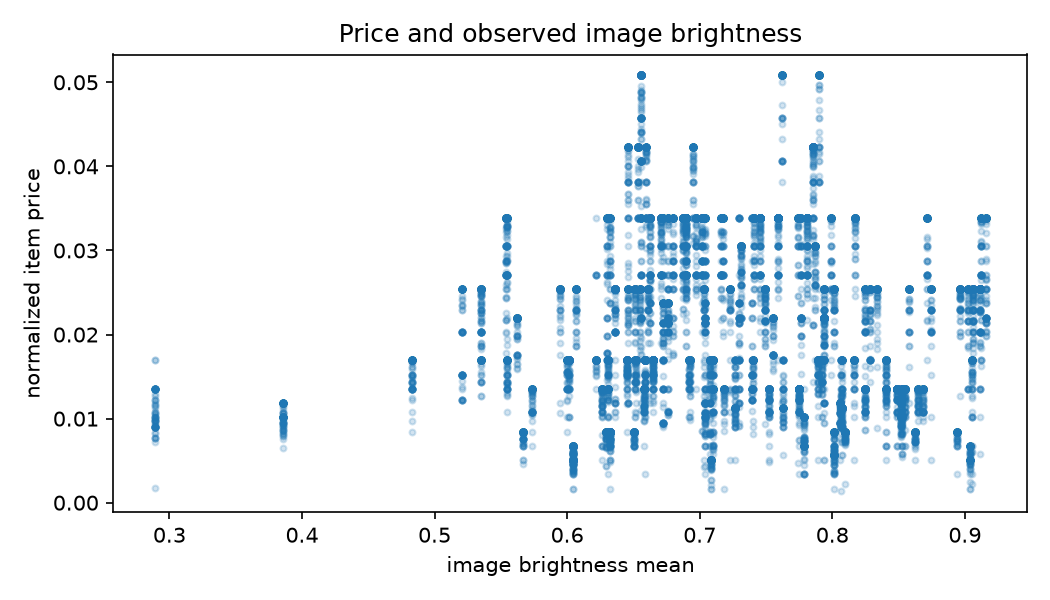

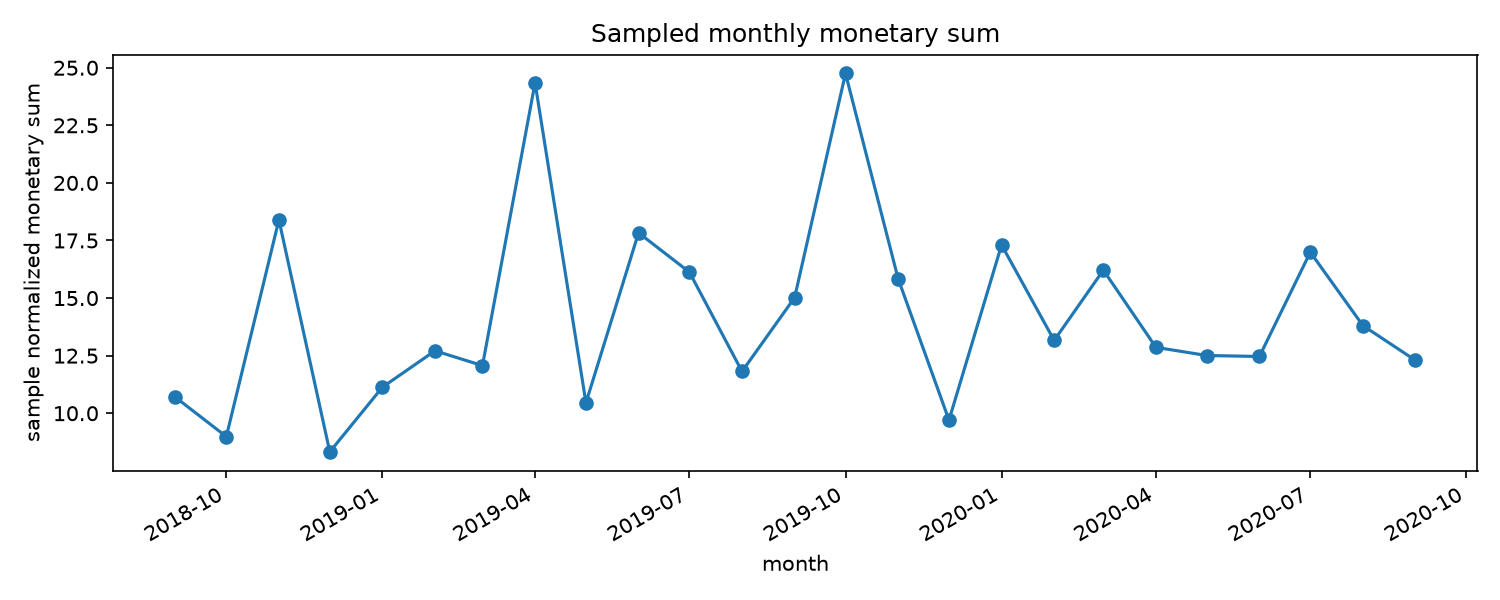

In [4]:
from src.analysis import eda
summary = eda(analyzer,project/'outputs')
print('price bounds:',summary['iqr_bounds'],'outliers:',summary['outlier_count'])
print('brightness bounds:',summary['brightness_iqr_bounds'],'outliers:',summary['brightness_outlier_count'])
print('correlations:',summary['correlations'])
display(analyzer.df[['price','name_length','image_mean']].agg(['mean','median','std']))
for filename in ['price-distributions.png','image-outliers.png','categories.png','correlations.png','scatter.png','monthly.png']:
    display(Image(filename=str(project/'outputs'/filename)))


## RFM과 세그먼트

기준일은 마지막 관측일의 다음 날입니다. Recency는 최근 관측 구매까지의 일수, Frequency는 서로 다른 관측 구매일 수, Monetary는 실제 행 가격 합계입니다. 같은 날 여러 상품을 산 행을 여러 주문으로 세지 않습니다.

평균 순위를 백분율로 바꿔 1~4점으로 변환하고 동률을 같은 점수로 유지합니다. 최근/고빈도/고금액이면 VIP, 그 외 고빈도는 Loyal, 최근 저빈도는 New, 나머지는 Churned로 명명합니다. 이름은 전체 생애 행동이 아닌 표본 규칙의 결과입니다.


reference: 2020-09-23


,customers,recency,frequency,monetary
segment,,,,
Churned,5626,549.155172,1.000000,0.030857
Loyal,41,427.804878,2.000000,0.058580
New,5629,179.923610,1.000000,0.031084
VIP,76,186.039474,2.013158,0.063465


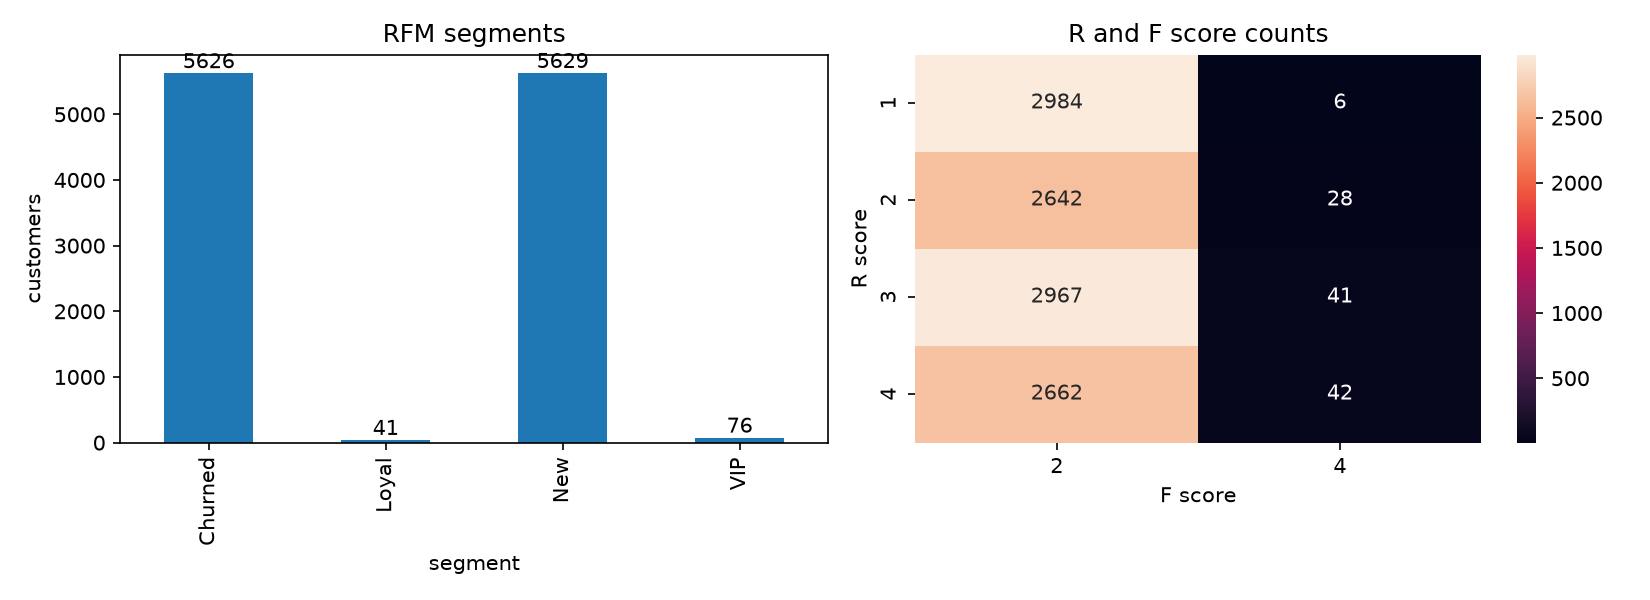

In [5]:
from src.analysis import rfm_analysis
rfm_result = rfm_analysis(analyzer,project/'outputs',interactive=True)
rfm = analyzer.calculate_rfm()
print('reference:',rfm_result['reference_date'])
display(rfm.groupby('segment').agg(customers=('monetary','size'),recency=('recency','mean'),frequency=('frequency','mean'),monetary=('monetary','mean')))
assert rfm.segment.nunique() >= 4
display(Image(filename=str(project/'outputs/rfm-segments.png')))


## 비즈니스 인사이트

1. 관측 휴면 고객의 재방문 실험

근거: Churned는 5,626명(49.47%)이고 평균 Recency는 549.2일입니다.
실행: 이 관측 세그먼트에 재방문 혜택을 노출하는 실험군/대조군을 구성하고 재구매일 수의 증가를 기대합니다.
검증: 표본 밖 거래가 누락되어 있으므로 실제 전체 거래 이력과 최근 방문 기록이 필요합니다. 이탈했다고 단정한 캠페인은 오분류일 수 있습니다.

2. 관측 고빈도/고금액 고객의 유지 전략

근거: VIP는 76명이고 표본 금액의 1.36%를 차지합니다. 평균 구매일 수는 2.01입니다.
실행: VIP에게 관심 카테고리 신상품을 우선 안내하는 실험으로 구매일 수 유지와 교차 구매를 기대합니다.
검증: 상품 마진/할인 비용/전체 고객 생애 구매를 추가로 확인해야 하며, 이 관측 표본만으로 LTV나 캠페인 수익을 계산할 수 없습니다.

3. 최근 관측 저빈도 고객의 다음 구매 유도

근거: New는 5,629명(49.50%)이고 관측 구매일 수는 평균 1.00입니다.
실행: 이 고객에게 첫 관측 상품과 관련된 카테고리를 추천하고 다음 관측 구매일 발생률의 증가를 확인합니다.
검증: New는 실제 신규 가입자가 아닌 RFM 규칙 이름입니다. 실제 가입일과 전체 거래를 확인하면 기존 고객으로 판명될 수 있습니다.


## H&M 구매 진입 코호트

계정 가입일이 없어 구매 진입을 최초 관측 구매로 정의한 비교 분석입니다. 실제 계정 가입월과 구분합니다. 관측된 달에 재구매가 없으면 0으로, 미래에 해당하는 달은 결측으로 남깁니다. 관측 거래가 없는 경과 월도 빠지지 않도록 전체 기간을 재색인합니다.


{'cohorts': 25, 'periods': 25, 'first_purchase_definition': 'first observed purchase in sampled time ranges; account signup dates unavailable', 'right_censored_cells': 300, 'period_zero_min': 1.0, 'period_zero_max': 1.0}


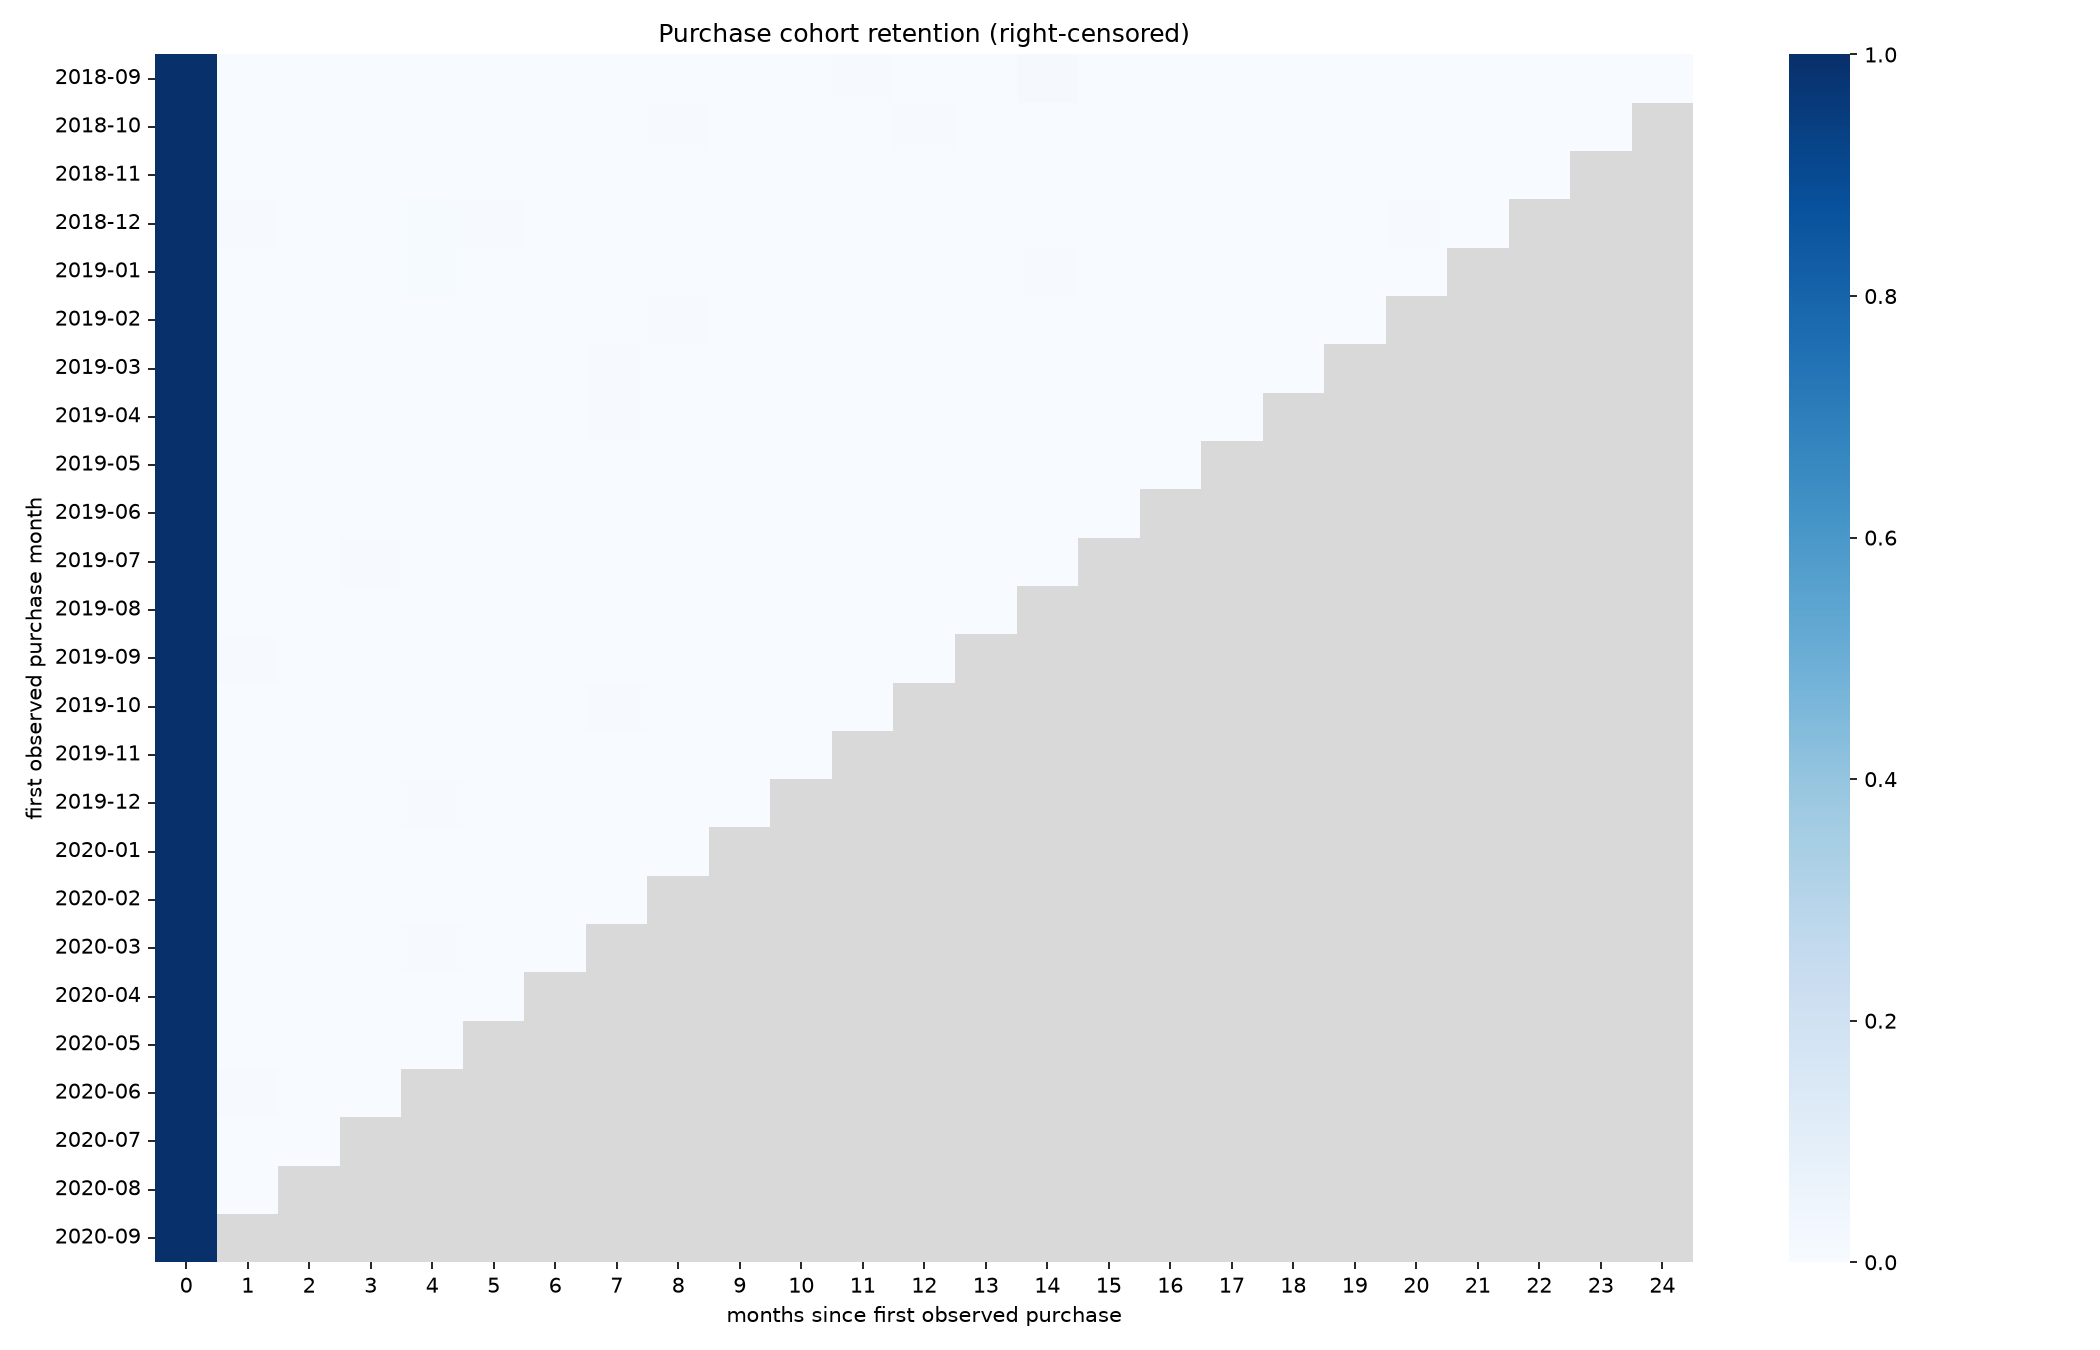

In [6]:
from src.analysis import cohort_analysis
cohort_result = cohort_analysis(analyzer,project/'outputs')
retention = analyzer.cohort_retention()
print(cohort_result)
np.testing.assert_allclose(retention[0],1.)
assert retention.isna().any().any()
display(Image(filename=str(project/'outputs/cohort.png')))


## 실제 멤버십 가입월의 재구매 코호트

공개 X5 RetailHero의 first_issue_date(최초 멤버십 카드 발급시각)를 가입 기준으로 사용했습니다. H&M의 웹 계정 가입일을 추정하거나 서로 다른 고객 ID를 합치지 않았습니다.

고객400,162명과 상품구매45,786,568행을 청크로 처리하고 발급시각 이후의 양수 상품량/비음수 금액 거래를 사용했습니다. 모든 날짜가 관측된2018-12/2019-01/2019-02만 비교했습니다. 부분 관측11월/3월과 미래 구간은0이 아닌 미관측으로 분리합니다.

가입월 구매를 마친 고객을 재구매 분모로 고정하므로0개월은100%입니다. 전체 신규가입 대비 가입월 결제 전환율64.59/66.74/72.86%는 별도로 표시합니다. 12월 집단의1개월90.75%/2개월93.84%는 월별 재구매율이므로 다음 달 복귀에 따라 높아질 수 있습니다.

원본과 필터/분모의 재현은 `python -m src.registration_cohort --download`이며 원자료를 재배포하지 않습니다. 여기서는 실행해 저장한 집계 결과를 다시 확인합니다.


registrations: 400162
purchase item rows: 45786568
observed window: 2018-11-21 2019-03-18


,signup_month,registrations,signup_month_payers,initial_conversion
0,2018-12,16659,10760,0.645897
1,2019-01,11311,7549,0.667403
2,2019-02,10643,7755,0.728648


,0,1,2
2018-12,1.0,0.907528,0.938383
2019-01,1.0,0.953504,NaN
2019-02,1.0,NaN,NaN


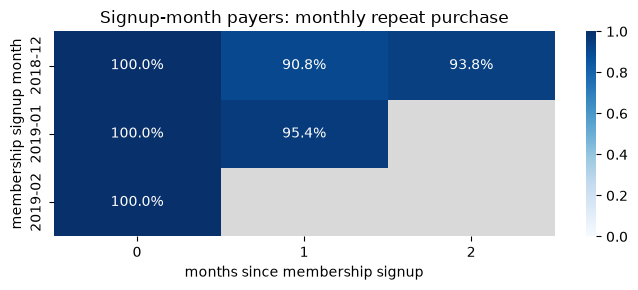

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
registration_project = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
with (registration_project/'outputs/registration/report.json').open() as stream:
    registration_report = json.load(stream)
print('registrations:',registration_report['registrations'])
print('purchase item rows:',registration_report['item_rows'])
print('observed window:',registration_report['observed_start'],registration_report['observed_end'])
display(pd.DataFrame(registration_report['conversion']))
registration_retention = pd.read_csv(registration_project/'outputs/registration/retention.csv',index_col=0)
display(registration_retention)
fig,ax = plt.subplots(figsize=(7,3))
sns.heatmap(registration_retention,annot=True,fmt='.1%',vmin=0,vmax=1,cmap='Blues',mask=registration_retention.isna(),ax=ax)
ax.set_facecolor('#d9d9d9')
ax.set(xlabel='months since membership signup',ylabel='membership signup month',title='Signup-month payers: monthly repeat purchase')
plt.tight_layout()
plt.show()
assert registration_retention.iloc[:,0].eq(1).all()
assert int(registration_retention.isna().sum().sum()) == 3


## 해석의 한계와 추가 확인

시간 분산 Range 표본은 확률 표본이나 전체 거래 이력이 아닙니다. 인기 상품 128개로 한정했으므로 고가/비인기 상품과 상품 외 구매가 누락됩니다. 표본의 월별 금액은 전체 회사 매출/성장률이 아니고, 낮은 관측 코호트 재구매율을 실제 고객 이탈 확률로 해석할 수 없습니다.

전체 이력과 실제 가입일을 확보한 뒤 동일 고객군의 RFM/코호트가 유지되는지, 캠페인 비용을 감안한 증분 구매가 있는지 추가 검증해야 합니다. Plotly 보너스 차트는 `outputs/rfm-interactive.html`을 브라우저에서 열어 확인합니다.
